In [1]:
import pandas as pd

In [2]:
from google.colab import files

uploaded = files.upload()

Saving IMDB Dataset.csv to IMDB Dataset.csv


In [5]:
df = pd.read_csv("IMDB Dataset.csv")

In [6]:
df.shape

(50000, 2)

In [7]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [8]:
df.isnull().sum()

,0
review,0
sentiment,0


In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.shape

(49582, 2)

# Pre-processing

1. Converting to lowercase

In [11]:
df["review"] = df["review"].str.lower()

2. Removing the URLs

In [12]:
import re

def remove_urls(text):
    text = re.sub(r"http\S+" , "", text)  # (pattern, repl, string) eg - https://www.google.com
    return text

df["review"] = df["review"].apply(remove_urls)

3. Removing punctuation

In [13]:
def remove_punctuations(text):
    text = re.sub(r"[^A-Za-z0-9\s]" , "", text) # A-Z a-z 0-9 \s
    return text

df["review"] = df["review"].apply(remove_punctuations)

In [14]:
df.head()

,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production br br the filmin...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically theres a family where a little boy j...,negative
4,petter matteis love in the time of money is a ...,positive


4. Removing HTML

In [15]:
def remove_html(text):
    text = re.sub(r"<.*?>" , "", text)
    return text

df["review"] = df["review"].apply(remove_html)

5. Removing the Stopwords

In [16]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [17]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

In [18]:
def remove_stopwords(text):
    tokens = word_tokenize(text)
    stop_words = stopwords.words("english")

    for word in tokens:
        if word in stop_words:
            text = text.replace(word, "")

    return text

df["review"] = df["review"].apply(remove_stopwords)

In [19]:
df.head()

,review,sentiment
0,e revewers nted wtchg 1 oz epode ll ho...,positive
1,wderful ltle producti br br filming techniqu...,positive
2,thought ths wderful wy spend tme o hot s...,positive
3,bsclly res fmly lttle boy jke thks res zom...,negative
4,petter mtte love time mey vully stunng fi...,positive


6. Stemming

In [20]:
from nltk.stem import PorterStemmer

In [21]:
def stemming(text):
    ps = PorterStemmer()
    stemmed_words = []

    tokens = word_tokenize(text)
    for token in tokens:
        stemmed_token = ps.stem(token)
        stemmed_words.append(stemmed_token)

    return " ".join(stemmed_words)

df["review"] = df["review"].apply(stemming)

In [22]:
df.head()

,review,sentiment
0,e revew nted wtchg 1 oz epod ll hook y rght ex...,positive
1,wder ltle producti br br film techniqu unssum ...,positive
2,thought th wder wy spend tme o hot summer week...,positive
3,bsclli re fmli lttle boy jke thk re zomb close...,negative
4,petter mtte love time mey vulli stunng film wt...,positive


7. Encoding

In [23]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["sentiment"] = le.fit_transform(df["sentiment"])

In [24]:
y = df["sentiment"]

In [25]:
y

,sentiment
0,1
1,1
2,1
3,0
4,1
...,...
49995,1
49996,0
49997,0
49998,0


8. Vectorization

In [26]:
df.head()

,review,sentiment
0,e revew nted wtchg 1 oz epod ll hook y rght ex...,1
1,wder ltle producti br br film techniqu unssum ...,1
2,thought th wder wy spend tme o hot summer week...,1
3,bsclli re fmli lttle boy jke thk re zomb close...,0
4,petter mtte love time mey vulli stunng film wt...,1


In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf = TfidfVectorizer(max_features=5000)

X = tf.fit_transform(df["review"])

# Dataset & Data Loaders

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [29]:
X_train.shape

(39665, 5000)

In [30]:
X_test.shape

(9917, 5000)

In [31]:
import torch
from torch.utils.data import TensorDataset, DataLoader

In [32]:
X_train = X_train.toarray()
X_test = X_test.toarray()

In [33]:
train_set = TensorDataset(
    torch.from_numpy(X_train).float(),
    torch.from_numpy(y_train.values).float()
)

test_set = TensorDataset(
    torch.from_numpy(X_test).float(),
    torch.from_numpy(y_test.values).float()
)

In [34]:
train_loader = DataLoader(train_set, shuffle=True, batch_size=64)
test_loader = DataLoader(test_set, shuffle=True, batch_size=64)

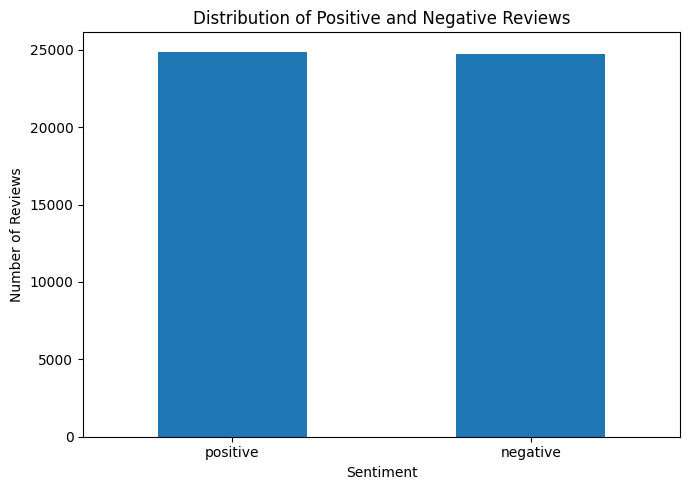

In [41]:
import matplotlib.pyplot as plt
import os

# Convert encoded labels back to their original names
sentiment_labels = df["sentiment"].map(
    dict(enumerate(le.classes_))
)

# Count positive and negative reviews
sentiment_counts = sentiment_labels.value_counts()

# Create results folder if it doesn't exist
os.makedirs("results", exist_ok=True)

# Plot
plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")

plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

# Save image
plt.savefig("results/sentiment_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Build our RNN

In [35]:
import torch.nn as nn
import torch.optim as optim

In [36]:
class RNN(nn.Module):

    def __init__(self, input_size, hidden_size=128, num_layers=1):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # RNN layer
        self.rnn = nn.RNN(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True
        )

        # Fully connected layer
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):

        # Convert 2D input into 3D input if necessary
        if x.dim() == 2:
            x = x.unsqueeze(1)

        # Initialize hidden state
        h0 = x.new_zeros(
            self.num_layers,
            x.size(0),
            self.hidden_size
        )

        # Forward pass through RNN
        out, _ = self.rnn(x, h0)

        # Take the output of the last timestep
        out = self.fc(out[:, -1, :])

        return out

In [37]:
input_size = X_train.shape[1]

model = RNN(input_size)

criterion = nn.BCELoss()

optimizer = optim.Adam(model.parameters())

# Training the RNN

In [38]:
epochs = 10

epoch_losses = []

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for Xb, yb in train_loader:

        optimizer.zero_grad()

        outputs = model(Xb)

        outputs = torch.sigmoid(outputs.squeeze(-1))

        loss = criterion(outputs, yb)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    epoch_losses.append(epoch_loss)

    print(f"Epoch [{epoch + 1}/{epochs}], Loss: {epoch_loss:.4f}")

Epoch [1/10], Loss: 0.3786
Epoch [2/10], Loss: 0.2644
Epoch [3/10], Loss: 0.2485
Epoch [4/10], Loss: 0.2415
Epoch [5/10], Loss: 0.2376
Epoch [6/10], Loss: 0.2339
Epoch [7/10], Loss: 0.2316
Epoch [8/10], Loss: 0.2303
Epoch [9/10], Loss: 0.2285
Epoch [10/10], Loss: 0.2276


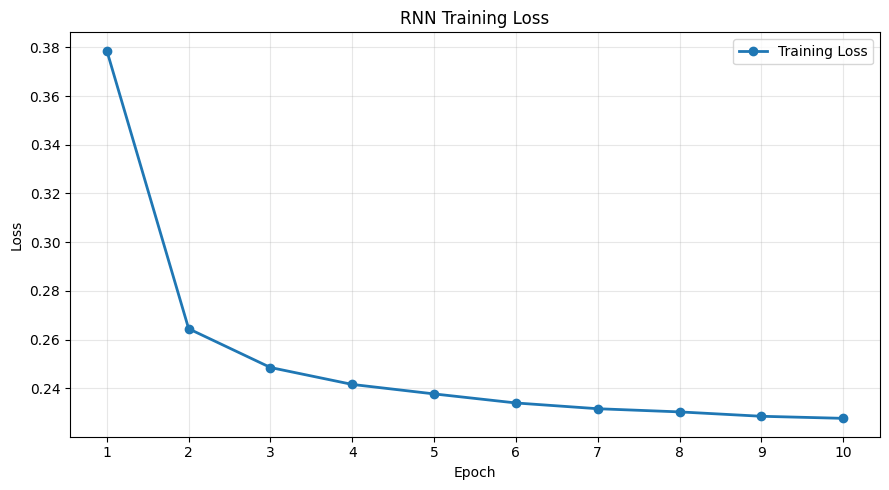

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(epoch_losses) + 1),
    epoch_losses,
    marker='o',
    linewidth=2,
    label='Training Loss'
)

plt.title('RNN Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.xticks(range(1, len(epoch_losses) + 1))
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    'training_loss.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

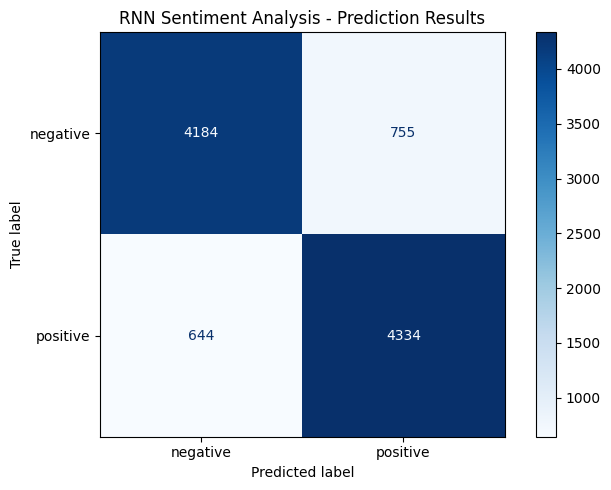

In [40]:
import matplotlib.pyplot as plt
import torch
import os

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()

all_predictions = []
all_actuals = []

with torch.no_grad():
    for Xb, yb in test_loader:

        # Get model output
        outputs = model(Xb)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(outputs.squeeze(-1))

        # Convert probabilities into 0 or 1
        predictions = (probabilities >= 0.5).float()

        all_predictions.extend(predictions.cpu().numpy())
        all_actuals.extend(yb.cpu().numpy())

# Create confusion matrix
cm = confusion_matrix(
    all_actuals,
    all_predictions,
    labels=[0, 1]
)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

fig, ax = plt.subplots(figsize=(7, 5))
display.plot(cmap="Blues", ax=ax, values_format="d")

plt.title("RNN Sentiment Analysis - Prediction Results")
plt.tight_layout()

# Save image
os.makedirs("results", exist_ok=True)
plt.savefig("results/prediction_results.png", dpi=300, bbox_inches="tight")
plt.show()

# Evaluate

In [42]:
model.eval()

with torch.no_grad():
    correct_vals = 0
    tot_vals = 0

    for Xb, yb in test_loader:
        Xb = Xb.unsqueeze(1)

        outputs = model(Xb)
        predicted = (torch.sigmoid(outputs.squeeze()) > 0.5).float() # if the probability is greater than 5 convert it into 1 of float value

        tot_vals += yb.size(0)
        correct_vals += (predicted == yb).sum().item()

    print(f"accuracy = {correct_vals/tot_vals*100}")

accuracy = 85.89291116265
